In [2]:
!pip install lime shap


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\tebos\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [10]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import lime
import lime.lime_tabular
import shap

In [2]:
#Load the dataset and explore
df = pd.read_csv("Customer_Churn.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics:")
display(df.describe(include="all"))

print("\nChurn Distribution:")
print(df["Churn"].value_counts())


Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN



Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [3]:
#convert target to numerical values
df["Churn"] = df["Churn"].replace({
    "Yes": 1,
    "No": 0
}).astype(int)

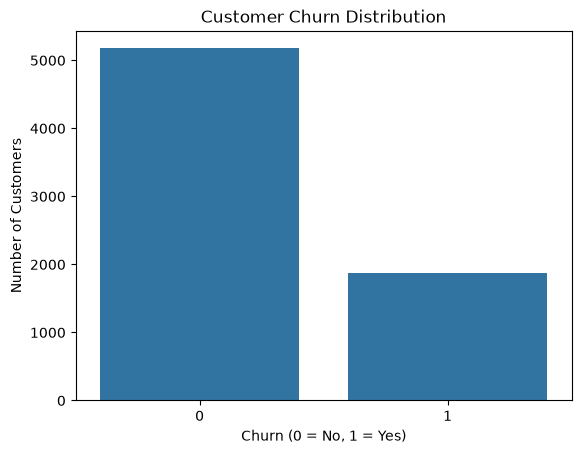

Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


In [4]:
#Visulize churn distribution
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

print(df["Churn"].value_counts(normalize=True) * 100)

The distribution is highly imbalance with number of  customers who did not churn severely greater than those who churn

**Split the dataset before preprocessing**


In [5]:
# Remove customer identifier if present
df = df.drop(columns=["customerID"], errors="ignore")

# Convert TotalCharges to numeric if present
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"], errors="coerce"
    )

X = df.drop(columns=["Churn"])
y = df["Churn"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (5634, 19)
Testing Shape: (1409, 19)


**Handle missing values and categorical features**

In [6]:
# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical Features:", num_cols)
print("Categorical Features:", cat_cols)

Numerical Features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\tebos\AppData\Local\Temp\ipykernel_34272\1588556712.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(


In [7]:
# Numerical preprocessing
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

**Train the Random Forest model**

In [8]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [12]:
# Make prediction
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]


In [13]:
#Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7637
Precision: 0.5485
Recall: 0.6203
F1 Score: 0.5822

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.55      0.62      0.58       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.77      0.76      0.77      1409



**Extract feature importance**

In [14]:
# Get trained Random Forest
rf_model = model.named_steps["classifier"]

# Get transformed feature names
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract importance
importance = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
3,num__TotalCharges,0.142587
1,num__tenure,0.132618
2,num__MonthlyCharges,0.121383
36,cat__Contract_Month-to-month,0.070944
18,cat__OnlineSecurity_No,0.038223
38,cat__Contract_Two year,0.035218
27,cat__TechSupport_No,0.033847
43,cat__PaymentMethod_Electronic check,0.029494
16,cat__InternetService_Fiber optic,0.028561
21,cat__OnlineBackup_No,0.017756


**Visualize Feature Importance**

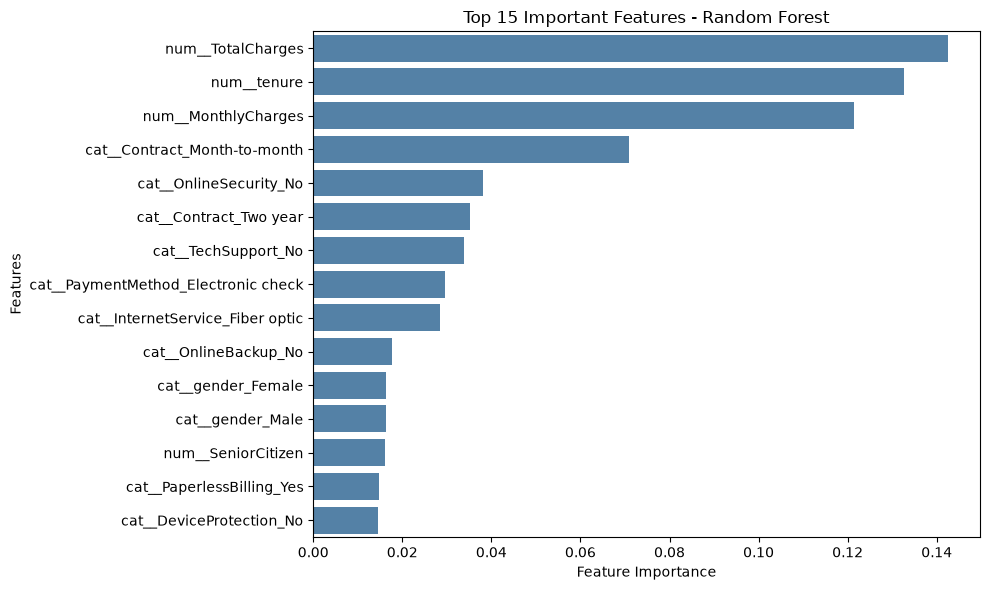

In [15]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

The features with higher importance scores contribute more to the model's predictions. based on the output, number of total charges,num_tenue, num_monthly charges and  contract montth to month are the most important features while cat deviceprotection, papaeless billing, gender and nenior citizen and the least important

**transformed data for LIME and SHAP**

In [16]:
# Transform data using fitted preprocessor
X_train_transformed = model.named_steps[
    "preprocessor"
].transform(X_train)

X_test_transformed = model.named_steps[
    "preprocessor"
].transform(X_test)

# Convert to DataFrames
X_train_processed = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

display(X_test_processed.head())

,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,...,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
437,-0.441773,1.608483,1.629976,2.707614,0.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
2280,2.263606,-0.996684,1.168725,-0.611506,1.0,0.0,1.0,0.0,1.0,0.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2235,-0.441773,0.346606,0.445324,0.399490,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4460,-0.441773,-0.589626,0.440347,-0.365546,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3761,-0.441773,1.608483,0.588013,1.588523,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


**Create the LIME explainer**

In [18]:
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_processed.values,
    feature_names=feature_names,
    class_names=["No Churn", "Churn"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

**explain the first customer in the test dataset**

In [29]:
sample_index = 0

sample = X_test_processed.iloc[sample_index].values

# Predict customer churn
prediction = rf_model.predict(
    sample.reshape(1, -1)
)

probability = rf_model.predict_proba(
    sample.reshape(1, -1)
)

print("Predicted Class:", prediction[0])
print("Churn Probability:", probability[0][1])

Predicted Class: 0
Churn Probability: 0.0


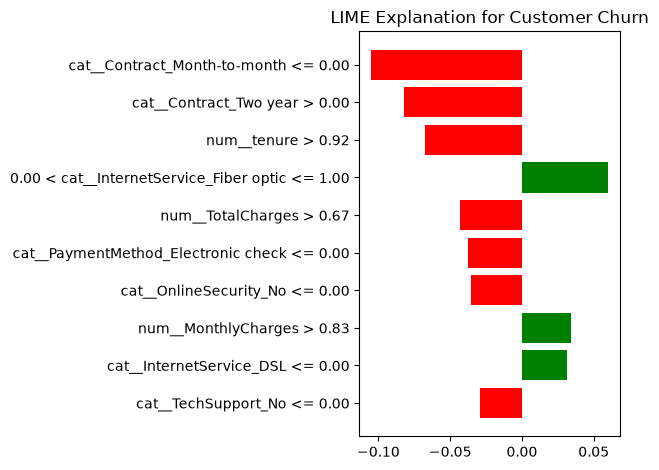

In [33]:
#Visualize Lime Explanation
fig = lime_exp.as_pyplot_figure(label=1)

plt.title("LIME Explanation for Customer Churn")
plt.tight_layout()
plt.show()

All the red bars are features that reduces churn while the green bars increases the chances of being churned. for instance, the customer does not have a month-to-month contract, strongly reducing predicted churn risk meaning they are less likely to leave teh company and also, having a two-year contract significantly reduces predicted churn risk.

Those with high monthly charges are more likely to leave the company. therefore, it increases predicted churn risk

**Using SHAP for Global and Local Interpretability**

In [34]:
#Create the SHAP explainer using the trained Random Forest
rf_model = model.named_steps["classifier"]

# Create SHAP Tree Explainer
shap_explainer = shap.TreeExplainer(rf_model)

# Use a subset for faster computation
X_shap = X_test_processed.iloc[:100].copy()

# Calculate SHAP values
shap_values = shap_explainer(X_shap)

print("SHAP Values Shape:", shap_values.values.shape)

SHAP Values Shape: (100, 45, 2)


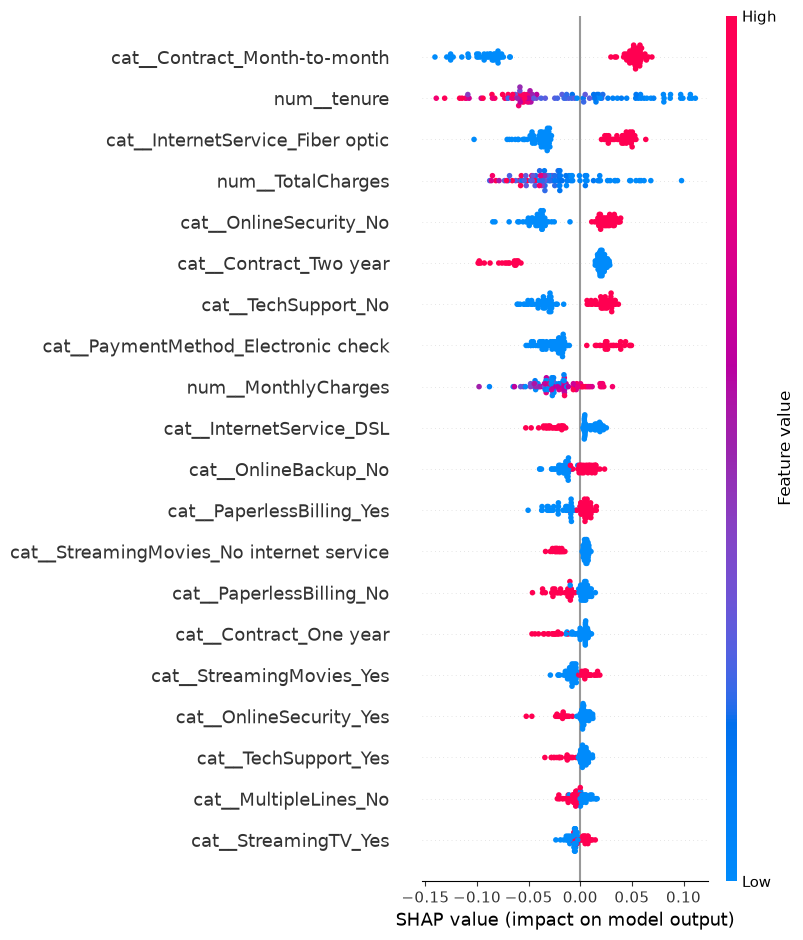

In [36]:
#SHAP summary plot
if shap_values.values.ndim == 3:
    shap_churn = shap_values[:, :, 1]
else:
    shap_churn = shap_values
    
shap.summary_plot(
    shap_churn.values,
    X_shap,
    feature_names=feature_names
)

In a summary, the contract type is the most influential feature. That is customers with month-to-month contracts are more likely to churn, while customers with two-year contracts are less likely to churn.

Also, customer tenure is another major factor. Customers who have stayed with the company longer generally have lower churn risk than newer customers.

Internet service and support services also influence churn. Fiber optic customers and customers without online security or technical support show higher predicted churn risk.

Payment method also matters. Customers using electronic checks tend to have higher predicted churn risk than customers using other payment methods.

In [40]:
#SHAP force plot
shap.initjs()

shap.plots.force(
    shap_churn[sample_index]
)

The SHAP force plot explains the Random Forest model's prediction for an individual customer. The baseline churn probability is approximately 50.03%, while the final predicted churn probability is close to 0%, indicating that the customer is highly unlikely to churn according to the model.